<a href="https://www.kaggle.com/code/mohammedaniba/mobilenetv3?scriptVersionId=360333366" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
!pip install gdown
!gdown --id 1KGpMhgPFCRE05dghX9DYIWZFqkYX7EhR

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1KGpMhgPFCRE05dghX9DYIWZFqkYX7EhR
From (redirected): https://drive.google.com/uc?id=1KGpMhgPFCRE05dghX9DYIWZFqkYX7EhR&confirm=t&uuid=dbbf5ecb-534f-4e31-9207-21b1d1d321be
To: /kaggle/working/PLANT_~2.zip
100%|████████████████████████████████████████| 725M/725M [00:12<00:00, 59.4MB/s]


In [2]:
import zipfile

with zipfile.ZipFile("PLANT_~2.zip", 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [ ]:
import os
import shutil
import random
from pathlib import Path
from tqdm import tqdm


In [5]:
import os
import shutil
import random

SOURCE_DIR = "/kaggle/working/dataset/Plant_leave_diseases_dataset_with_augmentation"
DEST_DIR = "/kaggle/working/split_dataset"

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15
SEED = 42

random.seed(SEED)


In [6]:
if os.path.exists(DEST_DIR):
    shutil.rmtree(DEST_DIR)

for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(DEST_DIR, split), exist_ok=True)


In [8]:
for class_name in os.listdir(SOURCE_DIR):

    class_path = os.path.join(SOURCE_DIR, class_name)

    if not os.path.isdir(class_path):
        continue

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if len(images) == 0:
        continue

    random.shuffle(images)

    total = len(images)
    train_end = int(total * TRAIN_RATIO)
    val_end = int(total * (TRAIN_RATIO + VAL_RATIO))

    train_imgs = images[:train_end]
    val_imgs = images[train_end:val_end]
    test_imgs = images[val_end:]

    for split in ["train", "val", "test"]:
        os.makedirs(os.path.join(DEST_DIR, split, class_name), exist_ok=True)

    for img in train_imgs:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(DEST_DIR, "train", class_name, img)
        )

    for img in val_imgs:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(DEST_DIR, "val", class_name, img)
        )

    for img in test_imgs:
        shutil.copy(
            os.path.join(class_path, img),
            os.path.join(DEST_DIR, "test", class_name, img)
        )

print("✅ Dataset split completed successfully.")


✅ Dataset split completed successfully.


In [9]:
for split in ["train", "val", "test"]:
    print(f"\n📂 {split.upper()} SET")
    split_path = os.path.join(DEST_DIR, split)

    for class_name in os.listdir(split_path):
        count = len(os.listdir(os.path.join(split_path, class_name)))
        print(f"{class_name:45} → {count}")



📂 TRAIN SET
Corn___Cercospora_leaf_spot Gray_leaf_spot    → 917
Corn___Common_rust                            → 1069
Tomato___Bacterial_spot                       → 1943
Tomato___healthy                              → 1430
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)    → 979
Strawberry___healthy                          → 917
Tomato___Leaf_Mold                            → 920
Soybean___healthy                             → 4627
Grape___Esca_(Black_Measles)                  → 1262
Tomato___Target_Spot                          → 1276
Potato___healthy                              → 911
Tomato___Tomato_Yellow_Leaf_Curl_Virus        → 4882
Potato___Late_blight                          → 906
Pepper,_bell___healthy                        → 1349
Corn___healthy                                → 1055
Tomato___Spider_mites Two-spotted_spider_mite → 1524
Corn___Northern_Leaf_Blight                   → 913
Tomato___Tomato_mosaic_virus                  → 898
Tomato___Early_blight                    

In [10]:
import os
import time
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score


In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)


Using device: cuda


In [13]:
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

val_tfms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


In [14]:
BASE = "/kaggle/working/split_dataset"

train_ds = datasets.ImageFolder(BASE + "/train", transform=train_tfms)
val_ds   = datasets.ImageFolder(BASE + "/val", transform=val_tfms)
test_ds  = datasets.ImageFolder(BASE + "/test", transform=val_tfms)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=4, pin_memory=True)

num_classes = len(train_ds.classes)
print("Number of classes:", num_classes)


Number of classes: 27


In [15]:
labels = [label for _, label in train_ds]
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)


load pre trained mobilenetv3

In [16]:
weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2
model = models.mobilenet_v3_large(weights=weights)

in_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(in_features, num_classes)

model = model.to(device)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 186MB/s]


In [17]:
for param in model.features.parameters():
    param.requires_grad = False


In [18]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.1
)

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=5
)

# ✅ Correct AMP scaler
scaler = torch.amp.GradScaler("cuda")


In [19]:
from sklearn.metrics import accuracy_score

def train_epoch(model, loader):
    model.train()
    total_loss = 0
    all_preds, all_targets = [], []

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # ✅ Updated AMP autocast
        with torch.amp.autocast("cuda"):
            outputs = model(images)
            loss = criterion(outputs, targets)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        preds = outputs.argmax(1)

        all_preds.extend(preds.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())

    acc = accuracy_score(all_targets, all_preds)
    return total_loss / len(loader), acc


def evaluate(model, loader):
    model.eval()
    total_loss = 0
    all_preds, all_targets = [], []

    with torch.no_grad():
        for images, targets in loader:
            images = images.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            # ✅ Updated AMP autocast
            with torch.amp.autocast("cuda"):
                outputs = model(images)
                loss = criterion(outputs, targets)

            total_loss += loss.item()
            preds = outputs.argmax(1)

            all_preds.extend(preds.detach().cpu().numpy())
            all_targets.extend(targets.detach().cpu().numpy())

    acc = accuracy_score(all_targets, all_preds)
    return total_loss / len(loader), acc


In [20]:
import copy

best_val_acc = 0
best_model_weights = copy.deepcopy(model.state_dict())

print("\n===== STAGE 1: Training Classifier Head =====\n")

for epoch in range(5):
    start_time = time.time()

    train_loss, train_acc = train_epoch(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    scheduler.step()

    epoch_time = time.time() - start_time

    print(f"Epoch {epoch+1}/5")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f}")
    print(f"Time: {epoch_time:.1f}s")
    print("-"*50)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_weights = copy.deepcopy(model.state_dict())
        print("✅ Best model updated!\n")



===== STAGE 1: Training Classifier Head =====

Epoch 1/5
Train Loss: 1.2334 | Train Acc: 0.8823
Val   Loss: 1.3762 | Val   Acc: 0.9616
Time: 185.2s
--------------------------------------------------
✅ Best model updated!

Epoch 2/5
Train Loss: 1.0707 | Train Acc: 0.9361
Val   Loss: 1.3782 | Val   Acc: 0.9489
Time: 178.3s
--------------------------------------------------
Epoch 3/5
Train Loss: 1.0263 | Train Acc: 0.9492
Val   Loss: 1.3125 | Val   Acc: 0.9747
Time: 176.3s
--------------------------------------------------
✅ Best model updated!

Epoch 4/5
Train Loss: 0.9873 | Train Acc: 0.9612
Val   Loss: 1.2942 | Val   Acc: 0.9774
Time: 177.3s
--------------------------------------------------
✅ Best model updated!

Epoch 5/5
Train Loss: 0.9636 | Train Acc: 0.9680
Val   Loss: 1.2756 | Val   Acc: 0.9808
Time: 176.8s
--------------------------------------------------
✅ Best model updated!



In [21]:
print("\n===== STAGE 2: Fine-Tuning Entire Network =====\n")

# 🔹 Unfreeze backbone
for param in model.features.parameters():
    param.requires_grad = True

# 🔹 Lower learning rate for fine-tuning (IMPORTANT)
optimizer = optim.AdamW(
    model.parameters(),
    lr=2e-5,                 # Reduced LR for stability
    weight_decay=1e-4
)

# 🔹 Longer cosine schedule
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=15
)

best_val_acc_stage2 = best_val_acc  # Continue from Stage 1 best

for epoch in range(15):
    start_time = time.time()

    train_loss, train_acc = train_epoch(model, train_loader)
    val_loss, val_acc = evaluate(model, val_loader)

    scheduler.step()

    epoch_time = time.time() - start_time

    print(f"[FineTune] Epoch {epoch+1}/15")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f} | Val   Acc: {val_acc:.4f}")
    print(f"LR: {optimizer.param_groups[0]['lr']:.6f}")
    print(f"Time: {epoch_time:.1f}s")
    print("-"*60)

    # 🔹 Save best model
    if val_acc > best_val_acc_stage2:
        best_val_acc_stage2 = val_acc
        best_model_weights = copy.deepcopy(model.state_dict())
        print("✅ New Best Model Saved!\n")

print(f"\n🔥 Best Validation Accuracy After Fine-Tuning: {best_val_acc_stage2:.4f}")



===== STAGE 2: Fine-Tuning Entire Network =====

[FineTune] Epoch 1/15
Train Loss: 0.9229 | Train Acc: 0.9808
Val   Loss: 1.2415 | Val   Acc: 0.9917
LR: 0.000020
Time: 201.1s
------------------------------------------------------------
✅ New Best Model Saved!

[FineTune] Epoch 2/15
Train Loss: 0.8886 | Train Acc: 0.9885
Val   Loss: 1.2252 | Val   Acc: 0.9952
LR: 0.000019
Time: 190.5s
------------------------------------------------------------
✅ New Best Model Saved!

[FineTune] Epoch 3/15
Train Loss: 0.8740 | Train Acc: 0.9908
Val   Loss: 1.2116 | Val   Acc: 0.9959
LR: 0.000018
Time: 191.9s
------------------------------------------------------------
✅ New Best Model Saved!

[FineTune] Epoch 4/15
Train Loss: 0.8626 | Train Acc: 0.9933
Val   Loss: 1.2037 | Val   Acc: 0.9973
LR: 0.000017
Time: 190.9s
------------------------------------------------------------
✅ New Best Model Saved!

[FineTune] Epoch 5/15
Train Loss: 0.8526 | Train Acc: 0.9952
Val   Loss: 1.1965 | Val   Acc: 0.9982
LR

In [22]:
model.load_state_dict(best_model_weights)
print("Loaded best fine-tuned model.")


Loaded best fine-tuned model.


In [23]:
test_loss, test_acc = evaluate(model, test_loader)

print("\n===== FINAL TEST RESULT =====")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")



===== FINAL TEST RESULT =====
Test Loss: 1.1810
Test Accuracy: 0.9989


In [24]:
model.load_state_dict(best_model_weights)

test_loss, test_acc = evaluate(model, test_loader)

print("\n===== FINAL TEST RESULT =====")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")



===== FINAL TEST RESULT =====
Test Loss: 1.1810
Test Accuracy: 0.9989


In [25]:
EXPORT_PATH = "/kaggle/working/mobilenetv3_best_model.pth"

torch.save({
    "model_state_dict": best_model_weights,
    "class_names": train_ds.classes
}, EXPORT_PATH)

print("✅ Model saved at:", EXPORT_PATH)


✅ Model saved at: /kaggle/working/mobilenetv3_best_model.pth


In [26]:
model.load_state_dict(best_model_weights)
model.eval()


MobileNetV3(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
        )
      )
    )
    (2): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 64, kernel_size=(1, 1), stride=(1, 1), bi

In [27]:
scripted_model = torch.jit.script(model)

TS_PATH = "/kaggle/working/mobilenetv3_scripted.pt"
scripted_model.save(TS_PATH)

print("✅ TorchScript model saved at:", TS_PATH)


✅ TorchScript model saved at: /kaggle/working/mobilenetv3_scripted.pt


In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report


In [30]:
model.load_state_dict(best_model_weights)
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        targets = targets.to(device)

        with torch.amp.autocast("cuda"):
            outputs = model(images)

        preds = outputs.argmax(1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())


In [31]:
print("\n===== CLASSIFICATION REPORT =====\n")

print(
    classification_report(
        all_targets,
        all_preds,
        target_names=train_ds.classes,
        digits=4
    )
)



===== CLASSIFICATION REPORT =====

                                               precision    recall  f1-score   support

   Corn___Cercospora_leaf_spot Gray_leaf_spot     1.0000    0.9892    0.9946       277
                           Corn___Common_rust     1.0000    1.0000    1.0000       331
                  Corn___Northern_Leaf_Blight     0.9896    1.0000    0.9948       285
                               Corn___healthy     1.0000    1.0000    1.0000       322
                            Grape___Black_rot     1.0000    1.0000    1.0000       325
                 Grape___Esca_(Black_Measles)     1.0000    1.0000    1.0000       384
   Grape___Leaf_blight_(Isariopsis_Leaf_Spot)     1.0000    1.0000    1.0000       301
                              Grape___healthy     1.0000    1.0000    1.0000       274
     Orange___Haunglongbing_(Citrus_greening)     1.0000    1.0000    1.0000      1541
                Pepper,_bell___Bacterial_spot     1.0000    1.0000    1.0000       275
      

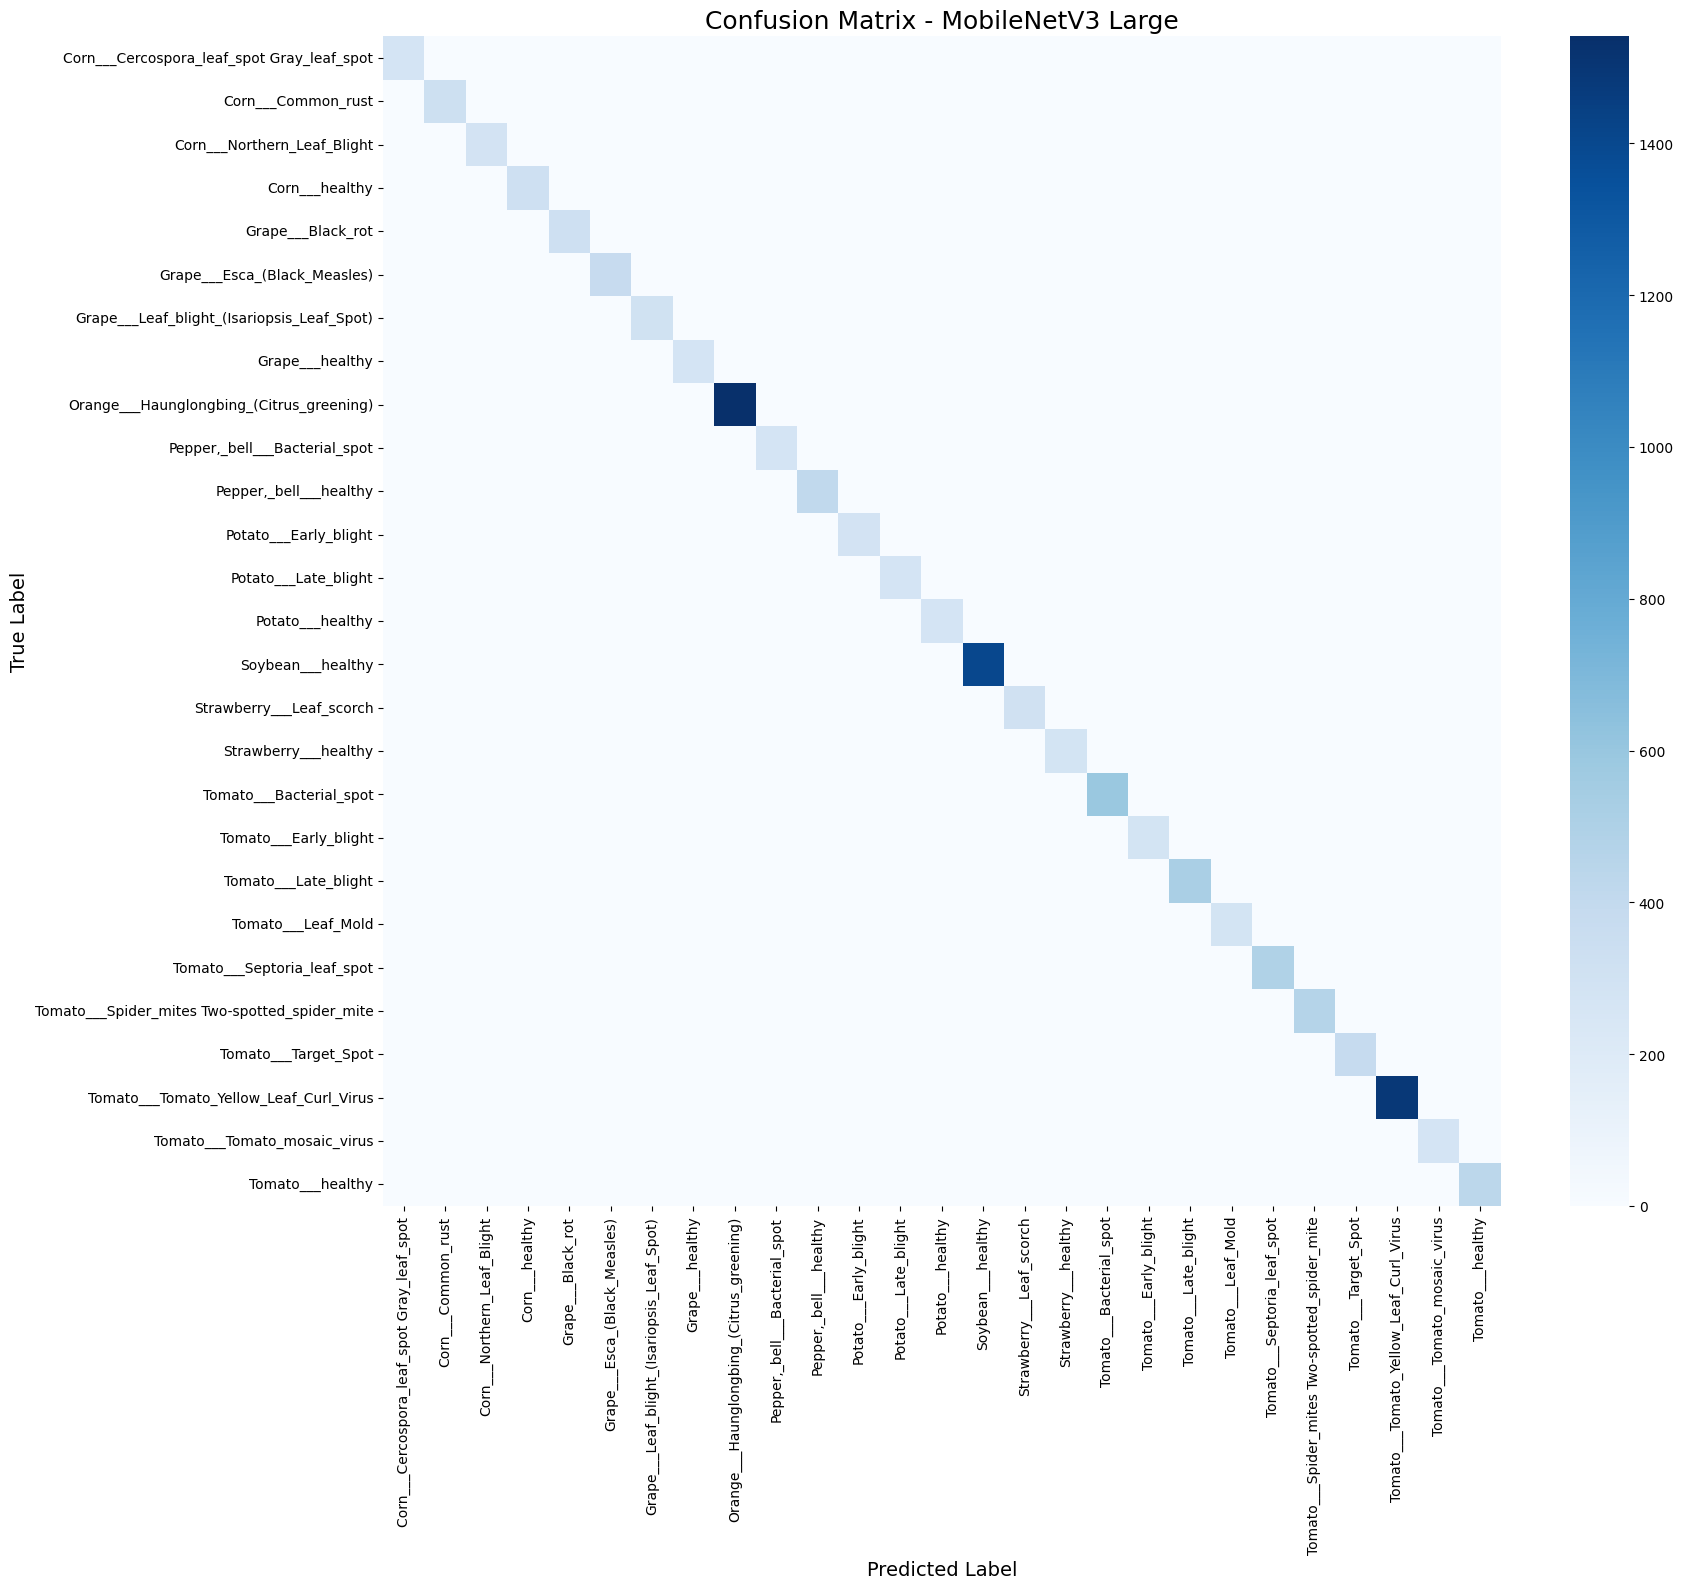

In [32]:
cm = confusion_matrix(all_targets, all_preds)

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=train_ds.classes,
    yticklabels=train_ds.classes
)

plt.title("Confusion Matrix - MobileNetV3 Large", fontsize=18)
plt.xlabel("Predicted Label", fontsize=14)
plt.ylabel("True Label", fontsize=14)
plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


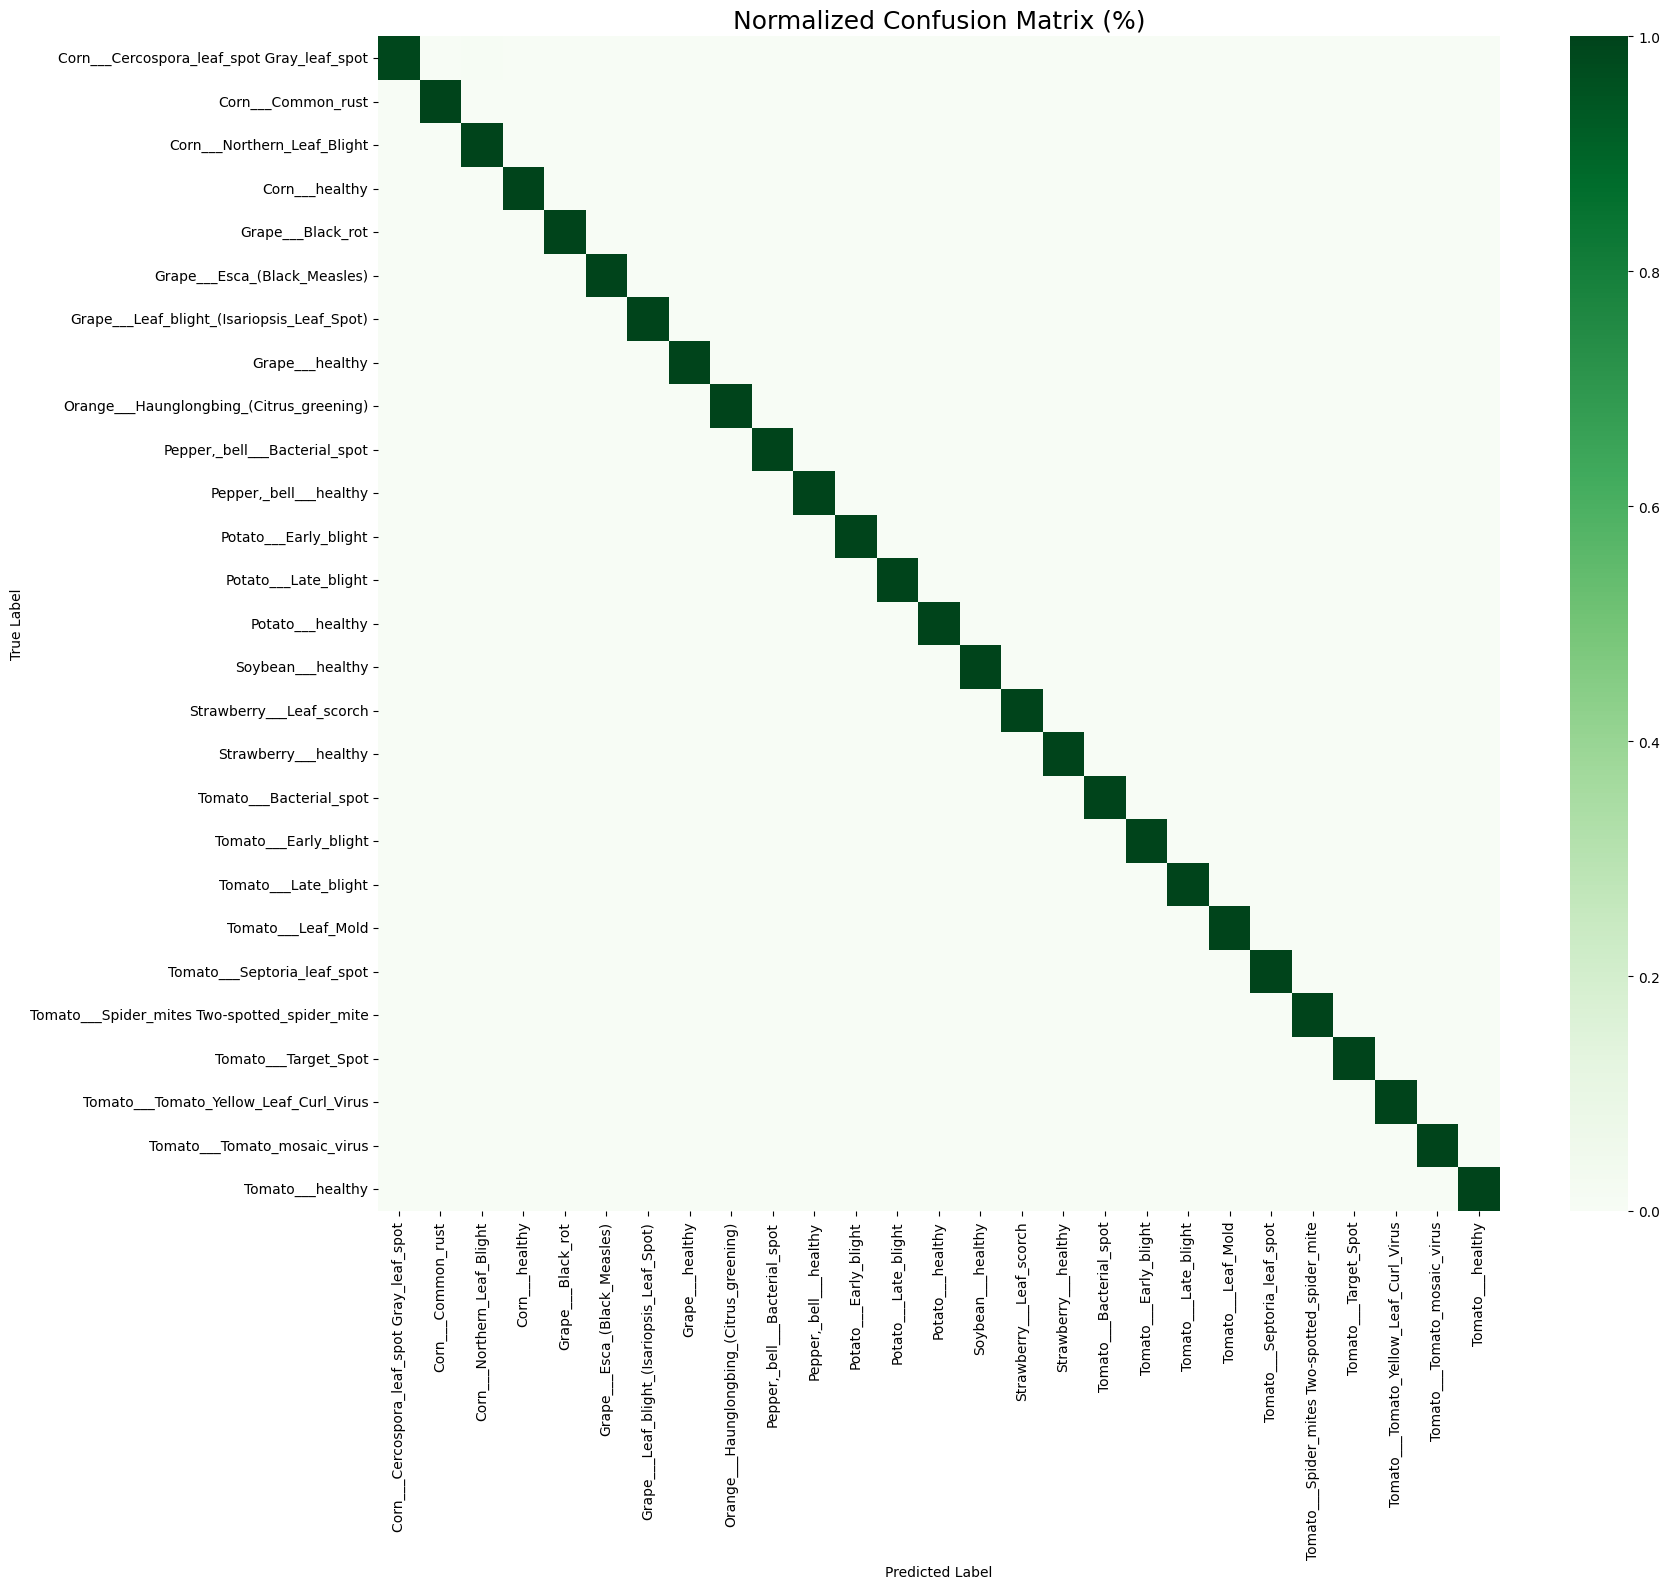

In [33]:
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(18, 16))

sns.heatmap(
    cm_norm,
    annot=False,
    cmap="Greens",
    xticklabels=train_ds.classes,
    yticklabels=train_ds.classes
)

plt.title("Normalized Confusion Matrix (%)", fontsize=18)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Use the existing ImageFolder datasets
datasets_dict = {
    "Train": train_ds,
    "Validation": val_ds,
    "Test": test_ds
}

# Dataset summary
summary = []

for split_name, dataset in datasets_dict.items():
    for class_idx, class_name in enumerate(dataset.classes):
        count = sum(
            1 for _, label in dataset.samples
            if label == class_idx
        )

        summary.append({
            "Split": split_name,
            "Class": class_name,
            "Image_Count": count
        })

dataset_summary = pd.DataFrame(summary)

print("Total number of classes:", len(train_ds.classes))
print("Total training images:", len(train_ds))
print("Total validation images:", len(val_ds))
print("Total testing images:", len(test_ds))
print("Total images:", len(train_ds) + len(val_ds) + len(test_ds))

display(dataset_summary)

# Save the summary for the report
dataset_summary.to_csv(
    "dataset_summary.csv", index=False
)

Total number of classes: 27
Total training images: 41837
Total validation images: 12710
Total testing images: 12779
Total images: 67326


,Split,Class,Image_Count
0,Train,Corn___Cercospora_leaf_spot Gray_leaf_spot,917
1,Train,Corn___Common_rust,1069
2,Train,Corn___Northern_Leaf_Blight,913
3,Train,Corn___healthy,1055
4,Train,Grape___Black_rot,1072
...,...,...,...
76,Test,Tomato___Spider_mites Two-spotted_spider_mite,469
77,Test,Tomato___Target_Spot,388
78,Test,Tomato___Tomato_Yellow_Leaf_Curl_Virus,1494
79,Test,Tomato___Tomato_mosaic_virus,271


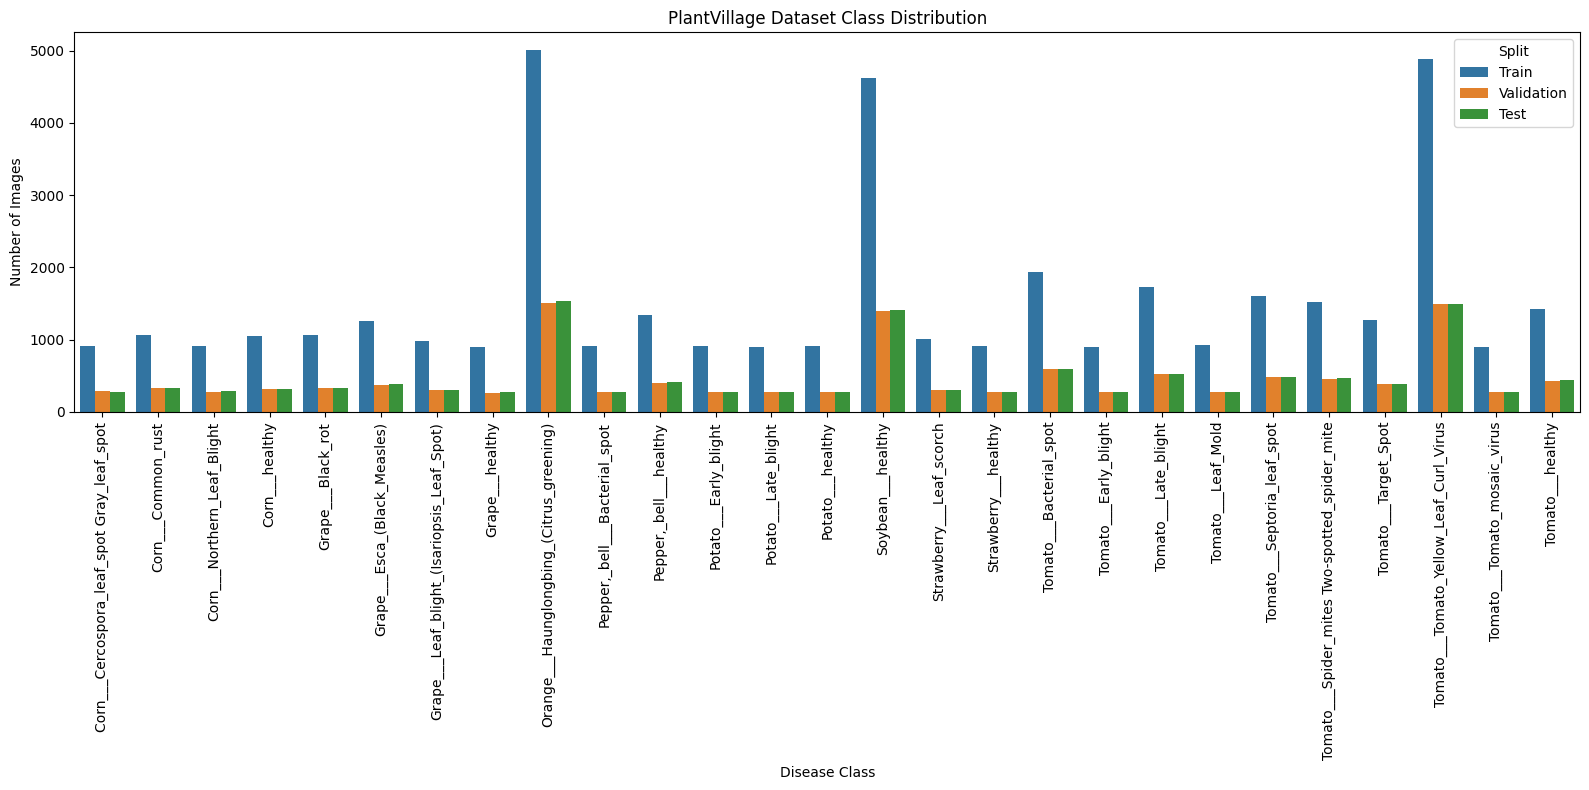

In [35]:
plt.figure(figsize=(16, 8))

sns.barplot(
    data=dataset_summary,
    x="Class",
    y="Image_Count",
    hue="Split"
)

plt.title("PlantVillage Dataset Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig("class_distribution.png", dpi=300)
plt.show()

In [37]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

In [40]:
import pandas as pd
from sklearn.metrics import classification_report

report = classification_report(
    all_targets,
    all_preds,
    target_names=train_ds.classes,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "classification_report.csv"
)

print("Classification report saved successfully!")

Classification report saved successfully!


Traceback (most recent call last):
  File "/usr/lib/python3.12/multiprocessing/queues.py", line 259, in _feed
    reader_close()
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 178, in close
    self._close()
  File "/usr/lib/python3.12/multiprocessing/connection.py", line 377, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor


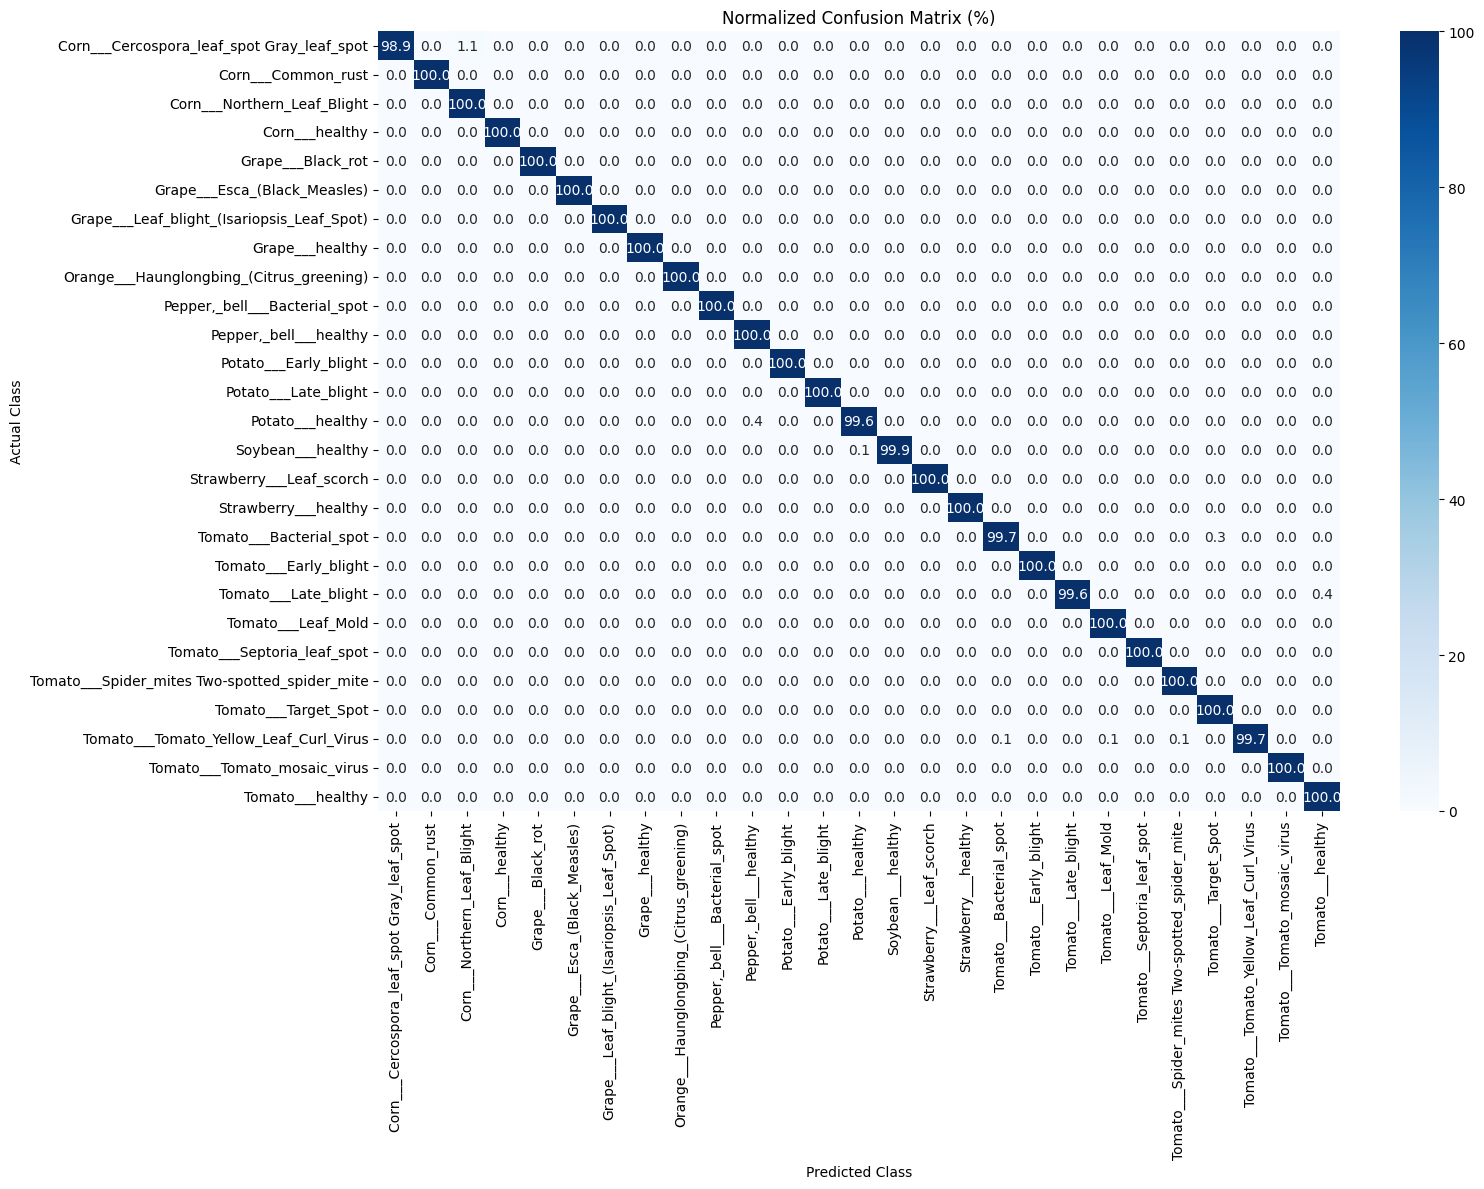

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_targets, all_preds)

cm_percent = cm.astype(float) / np.maximum(
    cm.sum(axis=1, keepdims=True), 1
) * 100

plt.figure(figsize=(16, 12))
sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=train_ds.classes,
    yticklabels=train_ds.classes
)

plt.title("Normalized Confusion Matrix (%)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("normalized_confusion_matrix_percent.png", dpi=300)
plt.show()

In [42]:
performance = pd.DataFrame([{
    "Model": "MobileNetV3 Large",
    "Test Accuracy (%)": test_acc * 100,
    "Test Loss": test_loss
}])

performance.to_csv("model_performance.csv", index=False)
print(performance)

               Model  Test Accuracy (%)  Test Loss
0  MobileNetV3 Large          99.890445   1.180979


In [45]:
import torch
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt

# Image path
IMAGE_PATH = "/kaggle/input/datasets/mohammedaniba/plant-image/9c144cd2-eeee-4a6f-9467-8a848186ca29.jpg"

# Trained model checkpoint
MODEL_PATH = "/kaggle/working/mobilenetv3_best_model.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load checkpoint
checkpoint = torch.load(
    MODEL_PATH,
    map_location=device,
    weights_only=False
)

class_names = checkpoint["class_names"]

# Rebuild model architecture
model = models.mobilenet_v3_large(weights=None)
model.classifier[3] = torch.nn.Linear(
    model.classifier[3].in_features,
    len(class_names)
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

# Preprocess image
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Predict disease category
image = Image.open(IMAGE_PATH).convert("RGB")
image_tensor = transform(image).unsqueeze(0).to(device)

with torch.inference_mode():
    outputs = model(image_tensor)
    probabilities = F.softmax(outputs, dim=1)[0]

predicted_idx = probabilities.argmax().item()
predicted_class = class_names[predicted_idx]
confidence = probabilities[predicted_idx].item() * 100

# Display result
print("=" * 40)
print("PLANT DISEASE PREDICTION")
print("=" * 40)
print("Predicted Category:", predicted_class)
print(f"Confidence Score: {confidence:.2f}%")

# Top 3 predictions
top_probs, top_indices = torch.topk(
    probabilities, min(3, len(class_names))
)

print("\nTop Predictions:")
for rank, (prob, idx) in enumerate(
    zip(top_probs, top_indices), start=1
):
    print

PLANT DISEASE PREDICTION
Predicted Category: Tomato___Bacterial_spot
Confidence Score: 78.14%

Top Predictions:
